## 01 - Data Exploration, Cleaning & Feature Engineering

**Module:** IT5022 Fundamentals of Machine Learning
**Dataset:** NYC Taxi Trip Duration (Kaggle, 2016 NYC TLC records) — https://www.kaggle.com/competitions/nyc-taxi-trip-duration
**Task:** Supervised regression — predict `trip_duration` (seconds) at the moment a trip starts.

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42          # fixed seed so every run gives the same sample and split
SAMPLE_SIZE = 200_000      # rows used for modelling
TEST_SIZE = 0.20

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../report/figures", exist_ok=True)

### 1. Load the data

In [3]:
DATA_PATH = "../data/raw/train.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["pickup_datetime", "dropoff_datetime"])
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded 1,458,644 rows x 11 columns


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [4]:
# Column types, missing values and duplicate IDs
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
print("Duplicate trip IDs:", df["id"].duplicated().sum())
overview

Duplicate trip IDs: 0


,dtype,missing,unique
id,str,0,1458644
vendor_id,int64,0,2
pickup_datetime,datetime64[us],0,1380222
dropoff_datetime,datetime64[us],0,1380377
passenger_count,int64,0,10
pickup_longitude,float64,0,23047
pickup_latitude,float64,0,45245
dropoff_longitude,float64,0,33821
dropoff_latitude,float64,0,62519
store_and_fwd_flag,str,0,2


### Attribute description

| Column | Meaning | Used as feature? |
|---|---|---|
| `id` | Unique trip identifier | No (identifier) |
| `vendor_id` | Data provider (1 or 2) | Yes |
| `pickup_datetime` | Meter start time | Yes, as hour / weekday / month |
| `dropoff_datetime` | Meter stop time | **No — dropoff minus pickup *is* the target (leakage)** |
| `passenger_count` | Driver-entered passenger count | Yes |
| `pickup_longitude/latitude` | Pickup GPS location | Yes |
| `dropoff_longitude/latitude` | Dropoff GPS location | Yes (destination is known when the trip is booked) |
| `store_and_fwd_flag` | Record held in vehicle memory before sending (Y/N) | Yes (0/1) |
| `trip_duration` | Trip length in seconds | **Target** |

### 2. Target variable

count    1458644.0
mean         959.5
std         5237.4
min            1.0
1%            87.0
50%          662.0
99%         3440.0
max      3526282.0
Name: trip_duration, dtype: float64


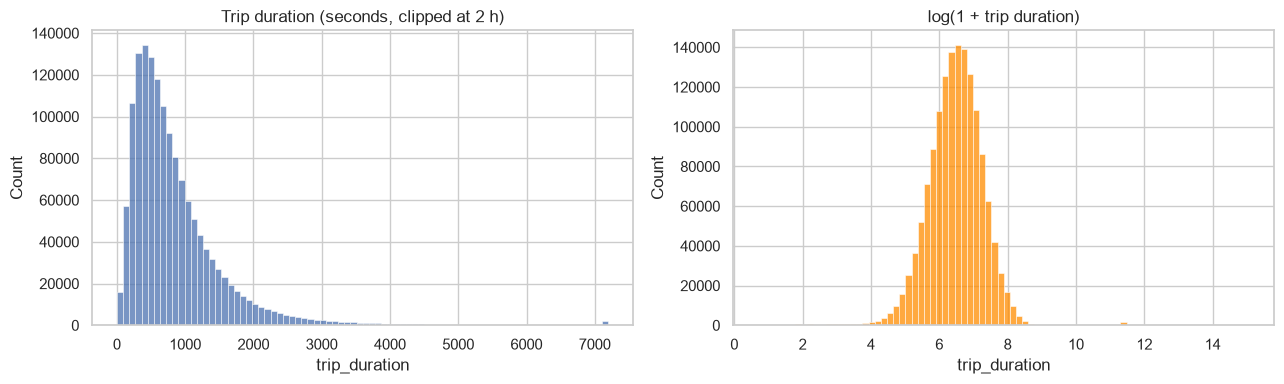

In [5]:
# Summary of the target, including the 1st and 99th percentiles
print(df["trip_duration"].describe(percentiles=[.01, .5, .99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["trip_duration"].clip(upper=7200), bins=80, ax=axes[0])
axes[0].set_title("Trip duration (seconds, clipped at 2 h)")
sns.histplot(np.log1p(df["trip_duration"]), bins=80, ax=axes[1], color="darkorange")
axes[1].set_title("log(1 + trip duration)")
plt.tight_layout()
plt.savefig("../report/figures/01_target_distribution.png", dpi=150)
plt.show()

The target is strongly right-skewed, with extreme values that are recording errors. After a log transform it is close
to bell-shaped, so both models will be trained on `log1p(trip_duration)`. Errors on the log scale are relative errors,
which matches the competition metric (RMSLE).

### 3. Exploratory analysis

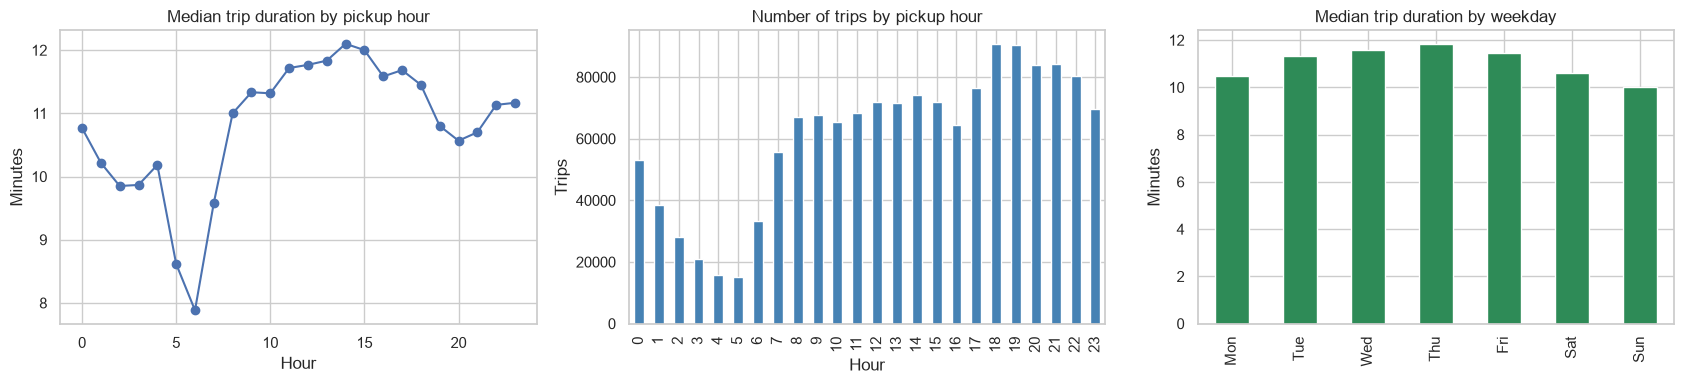

In [6]:
d = df.assign(hour=df["pickup_datetime"].dt.hour, weekday=df["pickup_datetime"].dt.dayofweek)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
d.groupby("hour")["trip_duration"].median().div(60).plot(ax=axes[0], marker="o")
axes[0].set(title="Median trip duration by pickup hour", xlabel="Hour", ylabel="Minutes")

d.groupby("hour").size().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set(title="Number of trips by pickup hour", xlabel="Hour", ylabel="Trips")

day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
d.groupby("weekday")["trip_duration"].median().div(60).set_axis(day_names).plot(kind="bar", ax=axes[2], color="seagreen")
axes[2].set(title="Median trip duration by weekday", xlabel="", ylabel="Minutes")
plt.tight_layout()
plt.savefig("../report/figures/01_time_patterns.png", dpi=150)
plt.show()

In [7]:
# Counts per value for the categorical columns
for col in ["vendor_id", "passenger_count", "store_and_fwd_flag"]:
    print(df[col].value_counts().sort_index().to_string(), "\n")

vendor_id
1    678342
2    780302 

passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1 

store_and_fwd_flag
N    1450599
Y       8045 



**Observations**

Starting with the target: a typical trip takes around 11 minutes (the median is 662 seconds), and 99% of trips are
over within an hour. The extremes don't make sense, though. The longest "trip" lasts about 41 days and the shortest
just one second, so these are clearly recording errors and need to be removed. There is also a small bump near the
24-hour mark (about 11.4 on the log scale), which looks like meters that were left running for a whole day.

The raw durations are heavily right-skewed, with a long tail of very long trips. Taking the log pulls this into
something close to a bell curve, which is why we model log(1 + duration) rather than the raw value.

Time of day makes a clear difference. Trips are quickest around 6 am, at roughly 8 minutes, and slowest around 2 pm,
at about 12 minutes, which fits with midday congestion. Durations creep up again late at night, but that is more
likely because people take longer trips at that hour than because of traffic.

Interestingly, the busiest hours are not the slowest ones. Demand peaks at 6–7 pm, with about 90k trips in each of
those hours, while the slowest trips happen at 2 pm. More trips on the road doesn't automatically mean slower trips.

The day of the week matters as well. Weekday trips take about a minute to a minute and a half longer than weekend
trips: Thursday is the slowest at around 11.8 minutes, and Sunday the quickest at about 10. That is what you would
expect with commuter and business traffic during the week.

On data quality, 65 trips have passenger counts that can't be right (0, or 7 to 9). `store_and_fwd_flag` is set to Y
for only 0.55% of trips, so it probably won't help the model much.

Taken together, hour of day and day of week look worth including as features, and the invalid records should be
cleaned out before training.

### 4. Data cleaning

Rules applied to the full dataset (each rule is counted so the effect can be reported):

1. **Location outside New York City** — pickup or dropoff outside a box covering the five boroughs and JFK/LaGuardia.
2. **Implausible duration** — under 60 seconds or over 2 hours.
3. **Invalid passenger count** — 0 or more than 6.
4. **No movement** — straight-line distance under 100 m.
5. **Impossible speed** — average speed above 100 km/h.

Rule 5 uses the trip duration, so it is only a *data-quality filter*: it removes records that cannot be real. The speed
itself is never given to a model.

In [8]:
def haversine_km(lat1, lon1, lat2, lon2):
    # Great-circle distance between two points on the Earth (in km)
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def clean(data):
    audit = {"start": len(data)}

    # Rule 1: both pickup and dropoff inside the NYC box
    lat_ok = lambda c: data[c].between(40.57, 40.92)
    lon_ok = lambda c: data[c].between(-74.15, -73.70)
    keep = lat_ok("pickup_latitude") & lat_ok("dropoff_latitude") & lon_ok("pickup_longitude") & lon_ok("dropoff_longitude")
    audit["outside_nyc"] = int((~keep).sum()); data = data[keep]

    # Rule 2: duration between 1 minute and 2 hours
    keep = data["trip_duration"].between(60, 7200)
    audit["duration_outside_60s_2h"] = int((~keep).sum()); data = data[keep]

    # Rule 3: 1 to 6 passengers
    keep = data["passenger_count"].between(1, 6)
    audit["invalid_passengers"] = int((~keep).sum()); data = data[keep]

    # Rule 4: moved at least 100 metres
    dist = haversine_km(data["pickup_latitude"], data["pickup_longitude"], data["dropoff_latitude"], data["dropoff_longitude"])
    keep = dist >= 0.1
    audit["under_100m"] = int((~keep).sum()); data, dist = data[keep], dist[keep]

    # Rule 5: average speed no more than 100 km/h
    speed = dist / (data["trip_duration"] / 3600)
    keep = speed <= 100
    audit["speed_over_100kmh"] = int((~keep).sum()); data = data[keep]

    audit["end"] = len(data)
    audit["retained_pct"] = round(100 * audit["end"] / audit["start"], 2)
    return data.copy(), audit

df_clean, audit = clean(df)
pd.Series(audit, name="rows").to_frame()

,rows
start,1458644.00
outside_nyc,4282.00
duration_outside_60s_2h,10544.00
invalid_passengers,18.00
under_100m,7391.00
speed_over_100kmh,30.00
end,1436379.00
retained_pct,98.47
